# ExamReview — From annotation evidence to adjudication

This notebook follows the data from the two evaluation workbooks to the final adjudication cases. It brings input validation, agreement analysis, shared-error diagnosis, final RDF comparison, and the JSON review queue into one reading path. All answers are computed from local inputs; no source files or human decisions are modified.

## Questions guiding the analysis

1. What was evaluated, how complete are the ratings, and how much do raters agree?
2. Is agreement greater on correct or incorrect relationships?
3. Which whole triples contain errors, and what do both raters say is wrong?
4. How do these judgments vary across Identifiers?
5. Does an incorrect predicate also have an incorrect direction?
6. What happens when an entity correction is explicitly unresolved?
7. How similar are the final RDF graphs, and what differs structurally?
8. Which unique cases need adjudication, what types are they, and where do types overlap?


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "ExamSource.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Run from the KGTestBench repository or its ExamReview folder.")
HELPER_DIR = ROOT / "ExamReview"
if str(HELPER_DIR) not in sys.path:
    sys.path.insert(0, str(HELPER_DIR))
from review_helpers import (
    load_review, align_reviews, shared_items, summarize_criteria, category_table,
    whole_triple_agreement, predicate_direction_counts, unresolved_flags,
    metrics, percent, file_sha256,
)

INPUTS = {r: ROOT / "data" / "inter-rater-reliability" / f"{r}-rdf.xlsx" for r in ["a1", "a2"]}
SHEET = "resultado_template_processado"
KEY = ["Identifier", "tripla_original"]
LABELS = {"label_corresponde_wikidata": "Label matches Wikidata", "entidade_correta": "Entity",
          "predicado_correto": "Predicate", "direcao_relacao_correta": "Direction",
          "fidelidade_semantica": "Semantic fidelity"}
SUBSTANTIVE = {c: title for c, title in LABELS.items() if c != "label_corresponde_wikidata"}
plt.rcParams.update({"font.size": 11, "figure.dpi": 120})
pd.set_option("display.max_columns", 12)

loaded = {r: load_review(p, SHEET, KEY, list(LABELS)) for r, p in INPUTS.items()}
audits = pd.DataFrame([record[1] for record in loaded.values()])
paired = align_reviews(loaded["a1"][0], loaded["a2"][0], KEY)
common = shared_items(paired, KEY)
relationships = common.loc[common.item_type == "relationship"].copy()
unmatched = paired.loc[paired["_merge"] != "both", KEY + ["_merge"]]
display(audits[["file", "rows_read", "excluded_without_triple", "items", "groups"]])
display(Markdown(f"**Matched items:** {len(common)}; **unmatched:** {len(unmatched)}. "
                 f"**Labels:** {(common.item_type == 'label').sum()}; **relationships:** {len(relationships)}."))
if not unmatched.empty:
    display(unmatched.head(20))
from review_helpers import agreement_matrix, rating_columns


,file,rows_read,excluded_without_triple,items,groups
0,a1-rdf.xlsx,592,0,592,10
1,a2-rdf.xlsx,592,0,592,10


**Matched items:** 592; **unmatched:** 0. **Labels:** 297; **relationships:** 295.

In [2]:
def grouped_percent_chart(table, columns, labels, title):
    """Compare percentages with explicit labels and a shared zero baseline."""
    fig, ax = plt.subplots(figsize=(10, max(3.5, len(table) * 0.85)), layout="constrained")
    y = np.arange(len(table))
    width = 0.7 / len(columns)
    for index, (column, label, color) in enumerate(zip(columns, labels, ["#285f91", "#bd7225"])):
        positions = y + (index - (len(columns) - 1) / 2) * width
        values = table[column].to_numpy(dtype=float)
        ax.barh(positions, values, height=width * 0.9, color=color, label=label)
        for pos, value in zip(positions, values):
            ax.text(1 if np.isnan(value) else value + 1, pos,
                    "undefined" if np.isnan(value) else f"{value:.1f}%", va="center", fontsize=9)
    ax.set(yticks=y, yticklabels=table.criterion, xlim=(0, 112),
           ylim=(-0.6, len(table)-0.4), xlabel="Percent (%)", title=title)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2)
    return fig


def count_bars(values, title):
    fig, ax = plt.subplots(figsize=(9, 3.5), layout="constrained")
    ax.barh(values.index, values.values, color="#285f91")
    for index, value in enumerate(values.values):
        ax.text(value + 0.5, index, str(int(value)), va="center")
    ax.set(xlim=(0, max(1, values.max()) * 1.15), xlabel="Relationship triples (count)", title=title)
    return fig

## 1. What was evaluated, and how much do raters agree?

Agreement includes both joint approvals and joint rejections. Kappa adjusts for the agreement expected from each rater's category proportions. Every metric uses only complete pairs for that criterion. Coverage is the share of matched items with two observed ratings.

,criterion,n_pairs,coverage_pct,agreement_pct,kappa_cohen,status
0,Label matches Wikidata,592,100.0000,99.8311,0.9966,calculated
1,Entity,592,100.0000,60.6419,0.2971,calculated
2,Predicate,592,100.0000,79.2230,0.5192,calculated
3,Direction,592,100.0000,99.3243,0.0000,calculated
4,Semantic fidelity,297,50.1689,63.2997,0.3001,calculated


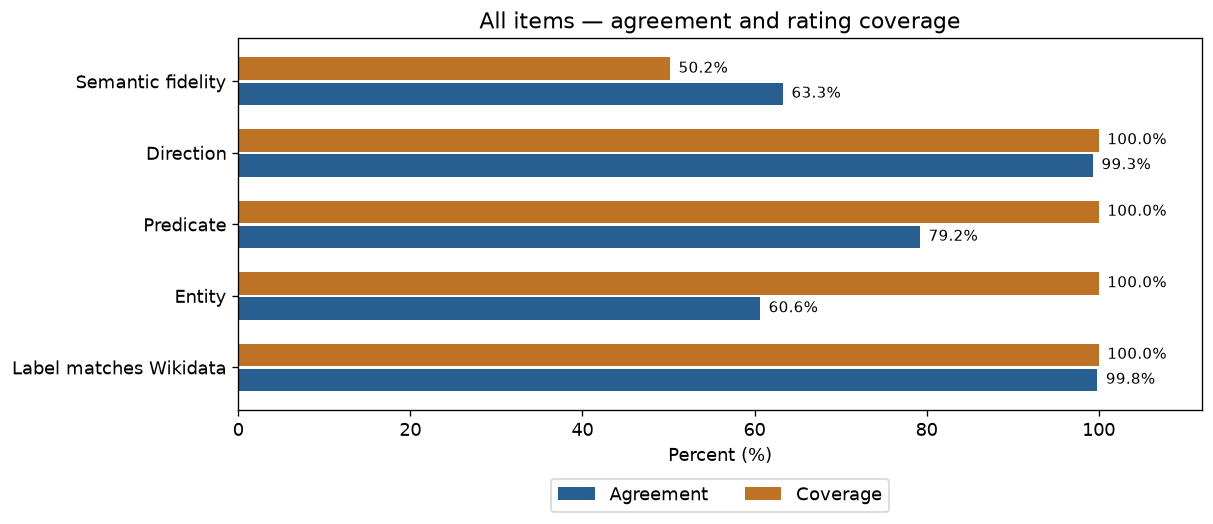

**Answer:** predicate agreement is 79.22% (κ=0.5192, n=592) after the a1 correction. Direction agreement is 99.32% with κ=0.0000. Inspect the marginal ratings: a high agreement percentage alone does not imply agreement beyond chance. Coverage differences mean the criteria need not describe identical sets of items.

In [3]:
criterion_summary = summarize_criteria(common, LABELS)
display(criterion_summary[["criterion", "n_pairs", "coverage_pct", "agreement_pct", "kappa_cohen", "status"]].round(4))
coverage_figure = grouped_percent_chart(criterion_summary, ["agreement_pct", "coverage_pct"],
                                       ["Agreement", "Coverage"], "All items — agreement and rating coverage")
plt.show()
predicate = criterion_summary.loc[criterion_summary.criterion == "Predicate"].iloc[0]
direction = criterion_summary.loc[criterion_summary.criterion == "Direction"].iloc[0]
display(Markdown(f"**Answer:** predicate agreement is {predicate.agreement_pct:.2f}% "
                 f"(κ={predicate.kappa_cohen:.4f}, n={predicate.n_pairs}) after the a1 correction. "
                 f"Direction agreement is {direction.agreement_pct:.2f}% with κ={direction.kappa_cohen:.4f}. "
                 "Inspect the marginal ratings: a high agreement percentage alone does not imply agreement beyond chance. "
                 "Coverage differences mean the criteria need not describe identical sets of items."))

### What drives the agreement percentage?

The matrices retain the underlying counts: rows are a1 and columns are a2. Both approvals and both rejections contribute to agreement; off-diagonal cells show the direction of disagreement. Panels share a color scale but can have different denominators because of missingness.

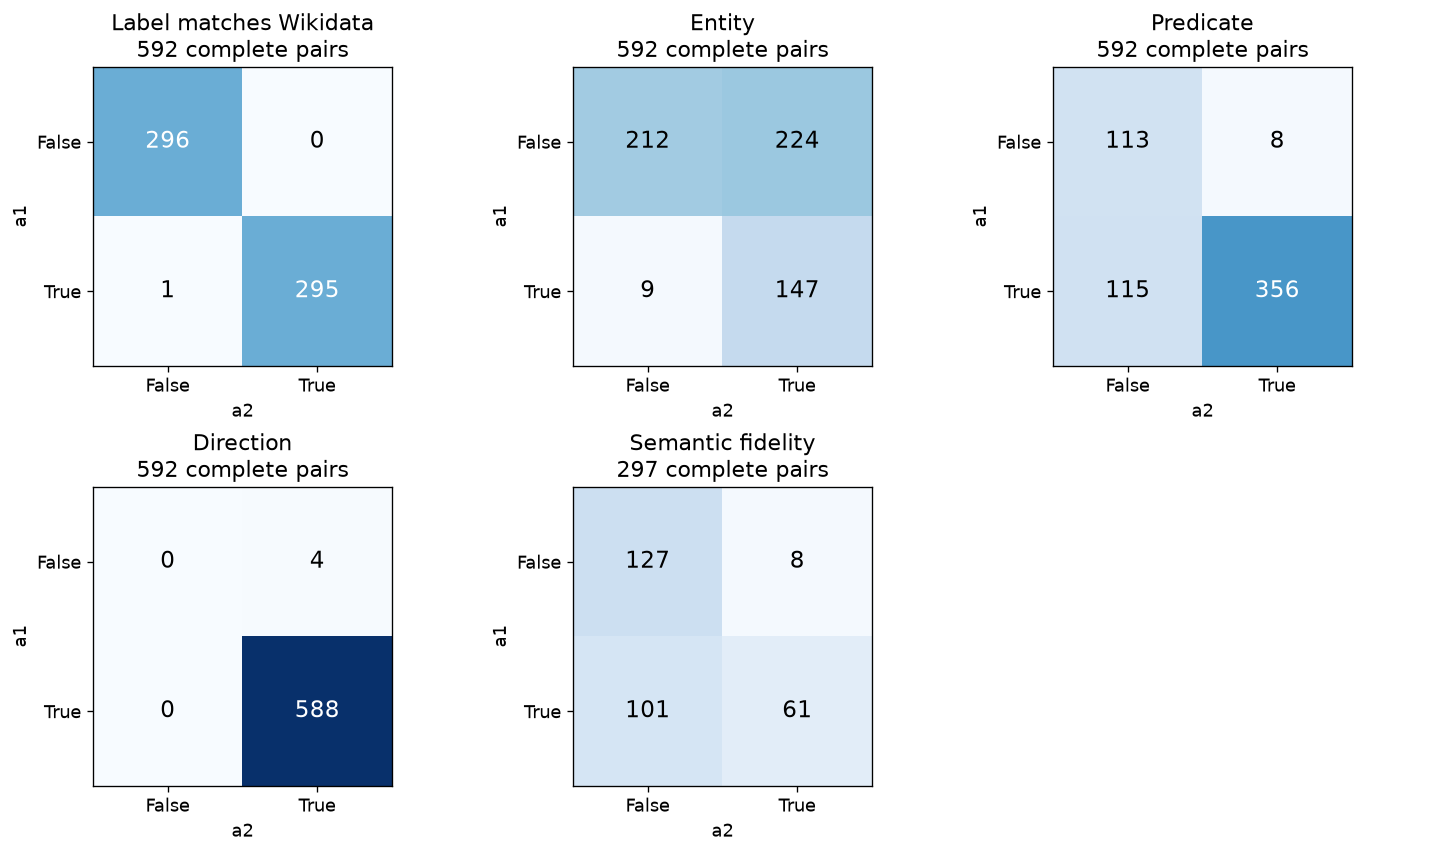

In [4]:
def draw_matrix(ax, matrix: np.ndarray, title: str, maximum: int) -> None:
    """Render one panel; plotting effects stay at the presentation boundary."""
    ax.imshow(matrix, cmap="Blues", vmin=0, vmax=maximum)
    for (i, j), count in np.ndenumerate(matrix):
        ax.text(j, i, str(count), ha="center", va="center", fontsize=14,
                color="white" if count > maximum / 2 else "black")
    ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=["False", "True"],
           yticklabels=["False", "True"], xlabel="a2", ylabel="a1",
           title=f"{title}\n{matrix.sum()} complete pairs")


def plot_matrices(matrices: list[np.ndarray], titles: list[str]):
    if not matrices or len(matrices) != len(titles):
        raise ValueError("Provide one title for each nonempty set of matrices.")
    rows = (len(matrices) + 2) // 3
    fig, axes = plt.subplots(rows, 3, figsize=(12, 3.5 * rows),
                             layout="constrained", squeeze=False)
    maximum = max(1, max(int(matrix.max()) for matrix in matrices))
    for ax, matrix, title in zip(axes.flat, matrices, titles):
        draw_matrix(ax, matrix, title, maximum)
    for ax in list(axes.flat)[len(matrices):]:
        ax.axis("off")
    return fig


matrices = [agreement_matrix(common, criterion) for criterion in LABELS]
fig = plot_matrices(matrices, list(LABELS.values()))
plt.show()

## 2. Is agreement greater on correct or incorrect relationships?

For complete pairs, TT means both True, FF means both False, and D means disagreement. **Positive agreement** = 2TT/(2TT+D); **negative agreement** = 2FF/(2FF+D). These symmetric measures compare the two categories.

The additional columns “both correct among any correct” = TT/(TT+D) and “both incorrect among any incorrect” = FF/(FF+D) answer the literal question of how often both raters endorse a judgment made by at least one. These are different denominators; neither measure is kappa.

,criterion,n_pairs,both_correct,both_incorrect,any_correct,any_incorrect,both_correct_among_any_correct_pct,both_incorrect_among_any_incorrect_pct,positive_agreement_pct,negative_agreement_pct
0,Entity,295,147,102,193,148,76.17,68.92,86.47,81.60
1,Predicate,295,60,113,182,235,32.97,48.09,49.59,64.94
2,Direction,295,292,0,295,3,98.98,0.00,99.49,0.00
3,Semantic fidelity,295,61,127,168,234,36.31,54.27,53.28,70.36


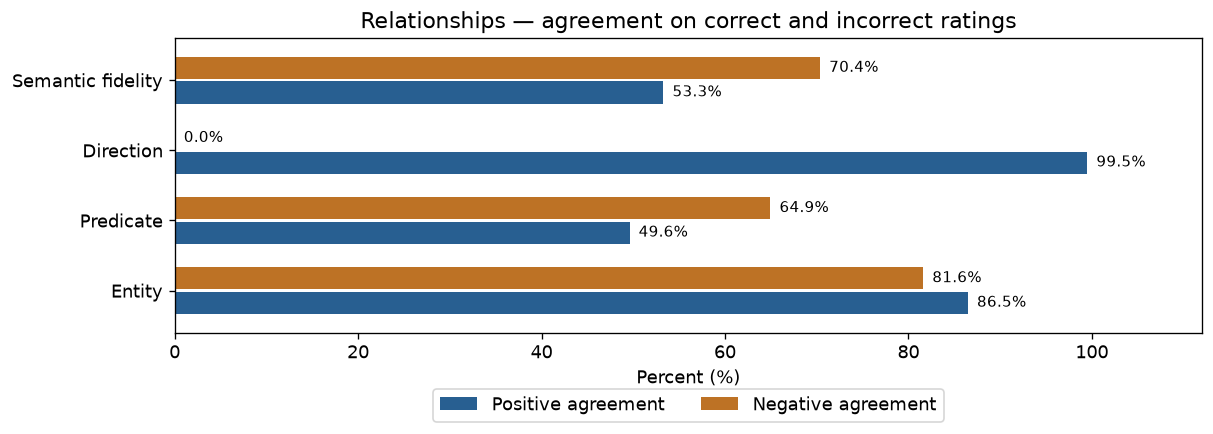

**Answer:** Entity: both reject 102/148 items rejected by either rater (68.92%); positive/negative agreement is 86.47%/81.60%. Predicate: both reject 113/235 items rejected by either rater (48.09%); positive/negative agreement is 49.59%/64.94%. Direction: both reject 0/3 items rejected by either rater (0.00%); positive/negative agreement is 99.49%/0.00%. Semantic fidelity: both reject 127/234 items rejected by either rater (54.27%); positive/negative agreement is 53.28%/70.36%.

In [5]:
category_summary = category_table(relationships, SUBSTANTIVE)
display(category_summary[["criterion", "n_pairs", "both_correct", "both_incorrect", "any_correct", "any_incorrect",
                          "both_correct_among_any_correct_pct", "both_incorrect_among_any_incorrect_pct",
                          "positive_agreement_pct", "negative_agreement_pct"]].round(2))
category_figure = grouped_percent_chart(category_summary, ["positive_agreement_pct", "negative_agreement_pct"],
                                       ["Positive agreement", "Negative agreement"], "Relationships — agreement on correct and incorrect ratings")
plt.show()
display(Markdown("**Answer:** " + " ".join(
    f"{r.criterion}: both reject {r.both_incorrect}/{r.any_incorrect} items rejected by either rater "
    f"({r.both_incorrect_among_any_incorrect_pct:.2f}%); positive/negative agreement is "
    f"{r.positive_agreement_pct:.2f}%/{r.negative_agreement_pct:.2f}%."
    for r in category_summary.itertuples())))

## 3. Do raters agree on which whole triples contain errors?

An exploratory whole-triple judgment is “fully correct” only if entity, predicate, direction, and semantic fidelity are all True. At least one False means “has an error.” All eight ratings must be observed. The label criterion is excluded because it is not informative for this composite on relationship rows. This definition is not an annotated whole-graph score.

Two raters can agree that a triple contains an error while disagreeing about the error criterion.

,outcome,count
0,Both fully correct,56
1,Both find an error,145
2,Only a1 fully correct,83
3,Only a2 fully correct,11


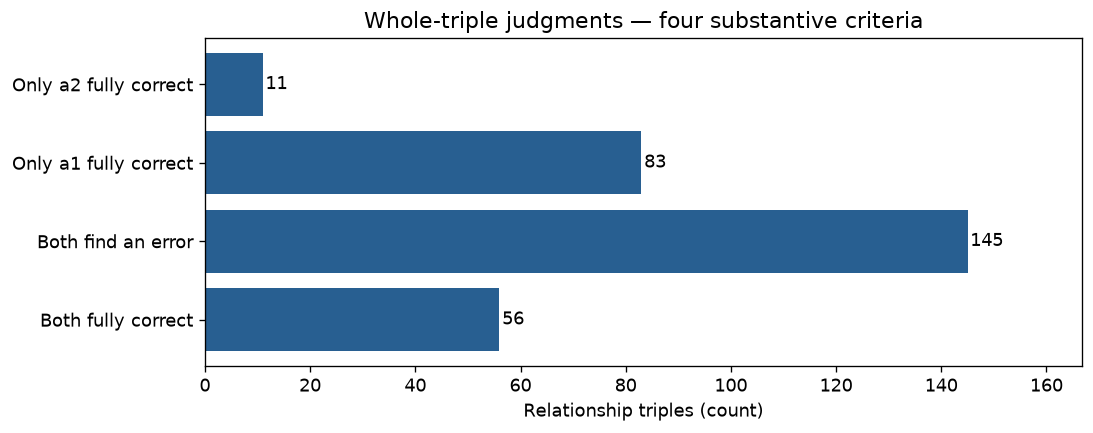

**Answer:** agreement is 68.14% (κ=0.3420) over 295/295 complete relationship triples. Both find an error in 145/239 triples rejected by at least one (60.67%). Of these, 142 share at least one error criterion. All four individual ratings match in 138 triples.

In [6]:
whole = whole_triple_agreement(relationships, list(SUBSTANTIVE))
OUTCOMES = {"both_correct": "Both fully correct", "both_incorrect": "Both find an error",
            "a1_correct_only": "Only a1 fully correct", "a2_correct_only": "Only a2 fully correct"}
whole_counts = whole[list(OUTCOMES)].sum()
whole_summary = metrics(whole.rename(columns={"correct_a1": "overall_a1", "correct_a2": "overall_a2"}),
                        "overall", "Whole triple")
display(pd.DataFrame({"outcome": list(OUTCOMES.values()), "count": whole_counts.to_numpy()}))
whole_figure = count_bars(whole_counts.rename(index=OUTCOMES), "Whole-triple judgments — four substantive criteria")
plt.show()
any_error = len(whole) - int(whole_counts.both_correct)
display(Markdown(
    f"**Answer:** agreement is {whole_summary['agreement_pct']:.2f}% "
    f"(κ={whole_summary['kappa_cohen']:.4f}) over {len(whole)}/{len(relationships)} complete relationship triples. "
    f"Both find an error in {whole_counts.both_incorrect}/{any_error} triples rejected by at least one "
    f"({percent(int(whole_counts.both_incorrect), any_error):.2f}%). "
    f"Of these, {int(whole.same_error_criterion.sum())} share at least one error criterion. "
    f"All four individual ratings match in {int(whole.identical_ratings.sum())} triples."
))

### 3.1 When both reject a triple, what is wrong?

The denominator below is **only relationship triples that both raters reject overall**, with all eight substantive ratings observed. For each criterion, “both flag error” means both selected False on that same triple. Counts overlap because one triple can contain several agreed errors; do not add them as separate triples.

The table also shows criteria rejected by only one rater within this jointly rejected subset. A triple can be jointly rejected without a shared reason. These are annotation patterns, not proof that an entity or predicate error caused the semantic-fidelity judgment.

In [7]:
from review_helpers import joint_error_details, joint_error_summary, joint_error_patterns

joint_errors = joint_error_details(relationships, SUBSTANTIVE)
joint_error_criteria = joint_error_summary(joint_errors, SUBSTANTIVE)
joint_error_combinations = joint_error_patterns(joint_errors)
display(joint_error_criteria.round(2))
display(joint_error_combinations.round(2))

joint_n = len(joint_errors)
shared_reason_n = int(joint_errors.shared_error_count.gt(0).sum())
same_reasons_n = int(joint_errors.same_error_set.sum())
display(Markdown(
    f"**Denominator:** {joint_n} jointly rejected relationship triples. "
    f"At least one error criterion is shared in {shared_reason_n}/{joint_n} "
    f"({percent(shared_reason_n, joint_n):.2f}%). "
    f"The entire set of rejected criteria matches in {same_reasons_n}/{joint_n} "
    f"({percent(same_reasons_n, joint_n):.2f}%). "
    "Sharing one reason is therefore different from agreeing on the complete diagnosis."
))

,criterion,jointly_rejected_triples,both_flag_error,both_flag_error_pct,only_a1_flags_error,only_a2_flags_error,neither_flags_error
0,Entity,145,102,70.34,28,2,13
1,Predicate,145,113,77.93,0,32,0
2,Direction,145,0,0.00,1,0,144
3,Semantic fidelity,145,127,87.59,0,18,0


,shared_error_pattern,triples,pct_of_jointly_rejected
0,Entity + Predicate + Semantic fidelity,75,51.72
1,Predicate + Semantic fidelity,27,18.62
2,Entity + Semantic fidelity,19,13.10
3,Predicate,7,4.83
4,Semantic fidelity,6,4.14
5,Entity,4,2.76
6,Entity + Predicate,4,2.76
7,No shared criterion,3,2.07


**Denominator:** 145 jointly rejected relationship triples. At least one error criterion is shared in 142/145 (97.93%). The entire set of rejected criteria matches in 82/145 (56.55%). Sharing one reason is therefore different from agreeing on the complete diagnosis.

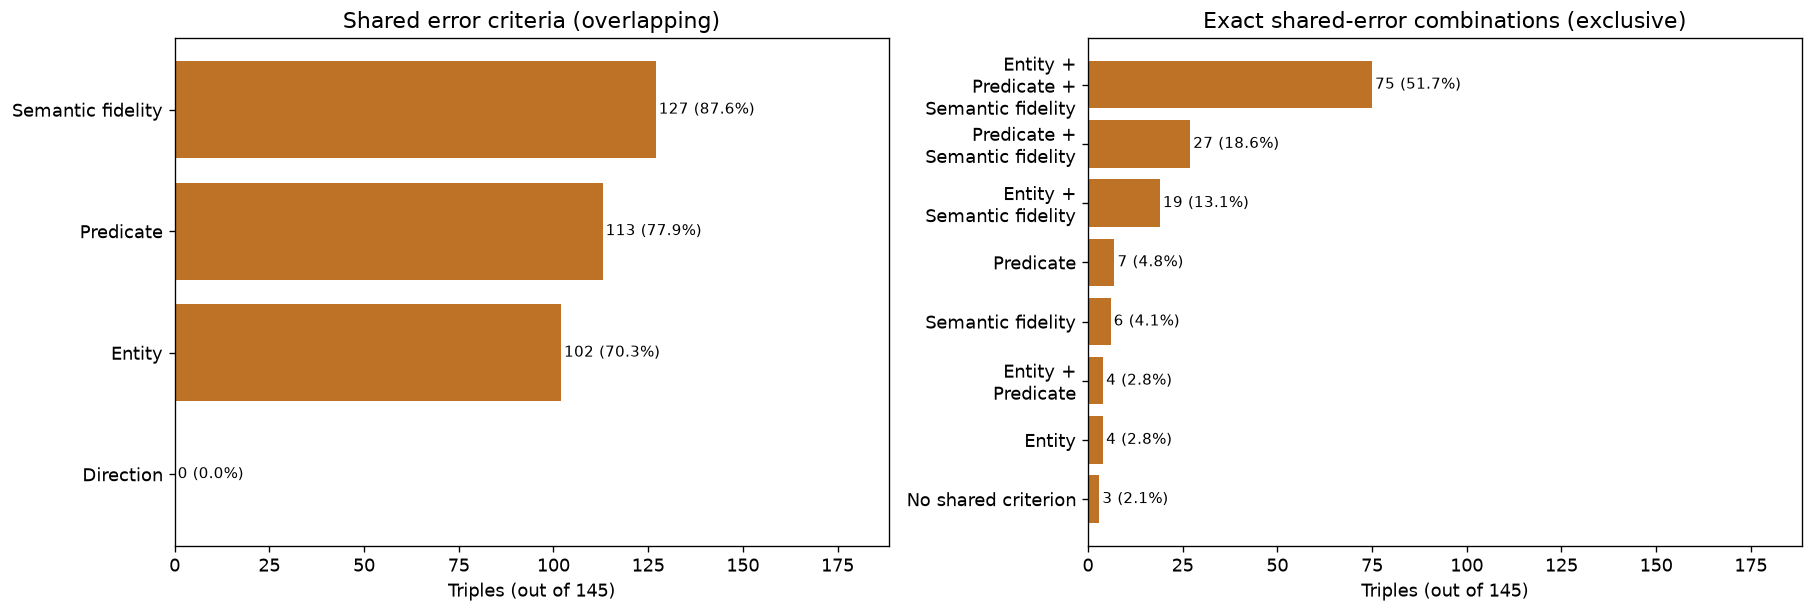

**Main finding:** Semantic fidelity is the most frequent shared rejection: 127/145 (87.59%). The most frequent exact combination of shared errors is **Entity + Predicate + Semantic fidelity**, with 75/145 triples (51.72%). A combination lists only jointly rejected criteria; a rater may additionally reject another criterion.

In [8]:
def plot_joint_errors(criteria, combinations, denominator):
    fig, axes = plt.subplots(1, 2, figsize=(15, 5), layout="constrained")
    panels = [
        (criteria.sort_values("both_flag_error"), "criterion", "both_flag_error", "Shared error criteria (overlapping)"),
        (combinations.sort_values("triples"), "shared_error_pattern", "triples", "Exact shared-error combinations (exclusive)"),
    ]
    for ax, (table, name, value, title) in zip(axes, panels):
        names = table[name].str.replace(" + ", " +\n", regex=False)
        ax.barh(names, table[value], color="#bd7225")
        for i, count in enumerate(table[value]):
            ax.text(count + 0.8, i, f"{count} ({percent(int(count), denominator):.1f}%)", va="center", fontsize=9)
        ax.set(xlim=(0, max(1, denominator) * 1.3), xlabel=f"Triples (out of {denominator})", title=title)
    return fig


joint_error_figure = plot_joint_errors(joint_error_criteria, joint_error_combinations, joint_n)
plt.show()
if joint_n:
    top = joint_error_criteria.sort_values("both_flag_error", ascending=False).iloc[0]
    combination = joint_error_combinations.iloc[0]
    display(Markdown(
        f"**Main finding:** {top.criterion} is the most frequent shared rejection: "
        f"{int(top.both_flag_error)}/{joint_n} ({top.both_flag_error_pct:.2f}%). "
        f"The most frequent exact combination of shared errors is **{combination.shared_error_pattern}**, "
        f"with {int(combination.triples)}/{joint_n} triples ({combination.pct_of_jointly_rejected:.2f}%). "
        "A combination lists only jointly rejected criteria; a rater may additionally reject another criterion."
    ))

### 3.2 Where do shared errors occur, and when do the reasons differ?

The Identifier table reports the number of jointly rejected triples and the count with a shared rejection for each criterion. The complete item-level evidence remains in `joint_errors`, including original keys, ratings, and comments.

`different_error_reasons` lists cases where both reject the whole triple but share no rejected criterion. `partially_shared_reasons` retains cases with at least one common reason but different full error sets. These cases need separate adjudication of the diagnosis, even though both agree that the triple has a problem.

In [9]:
shared_columns = [f"shared_error__{c}" for c in SUBSTANTIVE]
joint_errors_by_identifier = joint_errors.groupby("Identifier")[shared_columns].sum().rename(
    columns={f"shared_error__{c}": title for c, title in SUBSTANTIVE.items()})
joint_errors_by_identifier.insert(0, "jointly_rejected", joint_errors.groupby("Identifier").size())
display(joint_errors_by_identifier)

different_error_reasons = joint_errors.loc[joint_errors.shared_error_count.eq(0)].copy()
partially_shared_reasons = joint_errors.loc[
    joint_errors.shared_error_count.gt(0) & ~joint_errors.same_error_set].copy()
example_columns = KEY + (["relacao_traduzida_a1"] if "relacao_traduzida_a1" in joint_errors else [])
example_columns += ["errors_a1", "errors_a2", "shared_error_pattern"]
display(different_error_reasons[example_columns])
display(partially_shared_reasons[example_columns].head(10))

assert joint_n == int(whole_counts.both_incorrect)
assert int(joint_error_combinations.triples.sum()) == joint_n
assert shared_reason_n == int(whole.same_error_criterion.sum())
assert same_reasons_n + len(partially_shared_reasons) + len(different_error_reasons) == joint_n
for row in joint_error_criteria.itertuples():
    assert row.both_flag_error + row.only_a1_flags_error + row.only_a2_flags_error + row.neither_flags_error == joint_n
display(Markdown(
    f"**Diagnostic differences:** {len(partially_shared_reasons)} triples have partly shared reasons, "
    f"and {len(different_error_reasons)} have no shared error criterion. "
    "Review these separately from triples whose full error sets match. Counts and combinations reconcile."
))

,jointly_rejected,Entity,Predicate,Direction,Semantic fidelity
Identifier,,,,,
Amazon,19,15,17,0,17
Forest-Woodland,8,3,2,0,4
House-Building,23,19,21,0,19
Lake-Pond,18,10,11,0,18
Mercury,8,6,4,0,6
Mountain-Hill,12,10,11,0,11
Python,16,10,14,0,12
River-Stream,13,7,13,0,12
Saturn,14,12,6,0,14


,Identifier,tripla_original,relacao_traduzida_a1,errors_a1,errors_a2,shared_error_pattern
75,Forest-Woodland,wd:Q2615722 kg:lieOf wd:Q3957,Woodland -lieOf-> town,"(Entity,)","(Predicate, Semantic fidelity)",No shared criterion
89,Forest-Woodland,wd:Q72946 kg:beOf wd:Q15284,Forest -beOf-> municipality,"(Entity,)","(Predicate, Semantic fidelity)",No shared criterion
92,Forest-Woodland,wd:Q72946 kg:border wd:Q15284,Forest -border-> municipality,"(Entity,)","(Predicate, Semantic fidelity)",No shared criterion


,Identifier,tripla_original,relacao_traduzida_a1,errors_a1,errors_a2,shared_error_pattern
15,Amazon,wd:Q3884 kg:be wd:Q11016,Amazon -be-> technology,"(Entity, Semantic fidelity)","(Entity, Predicate, Semantic fidelity)",Entity + Semantic fidelity
31,Amazon,wd:Q40040 kg:be wd:Q580020,Amazonas -be-> 570,"(Entity, Predicate)","(Entity, Predicate, Semantic fidelity)",Entity + Predicate
33,Amazon,wd:Q40040 kg:be wd:Q927568,Amazonas -be-> 745,"(Entity, Predicate)","(Entity, Predicate, Semantic fidelity)",Entity + Predicate
37,Amazon,wd:Q40040 kg:beOf wd:Q199,Amazonas -beOf-> 1,"(Entity, Semantic fidelity)","(Entity, Predicate, Semantic fidelity)",Entity + Semantic fidelity
69,Forest-Woodland,wd:Q2615722 kg:be wd:Q37552616,Woodland -be-> Civil,"(Entity, Semantic fidelity)","(Predicate, Semantic fidelity)",Semantic fidelity
72,Forest-Woodland,wd:Q2615722 kg:beAbout wd:Q200,Woodland -beAbout-> 2,"(Entity,)","(Entity, Predicate, Semantic fidelity)",Entity
90,Forest-Woodland,wd:Q72946 kg:beOf wd:Q39850,Forest -beOf-> 19,"(Entity, Predicate, Semantic fidelity)","(Predicate, Semantic fidelity)",Predicate + Semantic fidelity
96,Forest-Woodland,wd:Q72946 kg:border wd:Q34147,Forest -border-> Flemish Dutch,"(Entity, Semantic fidelity)","(Entity, Predicate, Semantic fidelity)",Entity + Semantic fidelity
126,House-Building,wd:Q3947 kg:be wd:Q985488,house -be-> residential community,"(Entity, Semantic fidelity)","(Entity, Predicate, Semantic fidelity)",Entity + Semantic fidelity
136,House-Building,wd:Q3947 kg:rangeFrom wd:Q29718088,house -rangeFrom-> r,"(Entity,)","(Entity, Predicate, Semantic fidelity)",Entity


**Diagnostic differences:** 60 triples have partly shared reasons, and 3 have no shared error criterion. Review these separately from triples whose full error sets match. Counts and combinations reconcile.

## 4. Is agreement concentrated in one Identifier?

The following groups the whole-triple judgments defined above. Counts show volume; agreement rates account for differing group sizes. Every group remains visible, including small groups. This is descriptive rather than a statistically established ranking.

,both_correct,both_incorrect,a1_correct_only,a2_correct_only,n_triples,agreement_pct
Identifier,,,,,,
Amazon,5,19,4,0,28,85.71
Forest-Woodland,5,8,9,0,22,59.09
House-Building,6,23,13,1,43,67.44
Lake-Pond,6,18,8,1,33,72.73
Mercury,6,8,7,5,26,53.85
Mountain-Hill,5,12,4,1,22,77.27
Python,6,16,10,3,35,62.86
River-Stream,8,13,4,0,25,84.0
Saturn,4,14,14,0,32,56.25


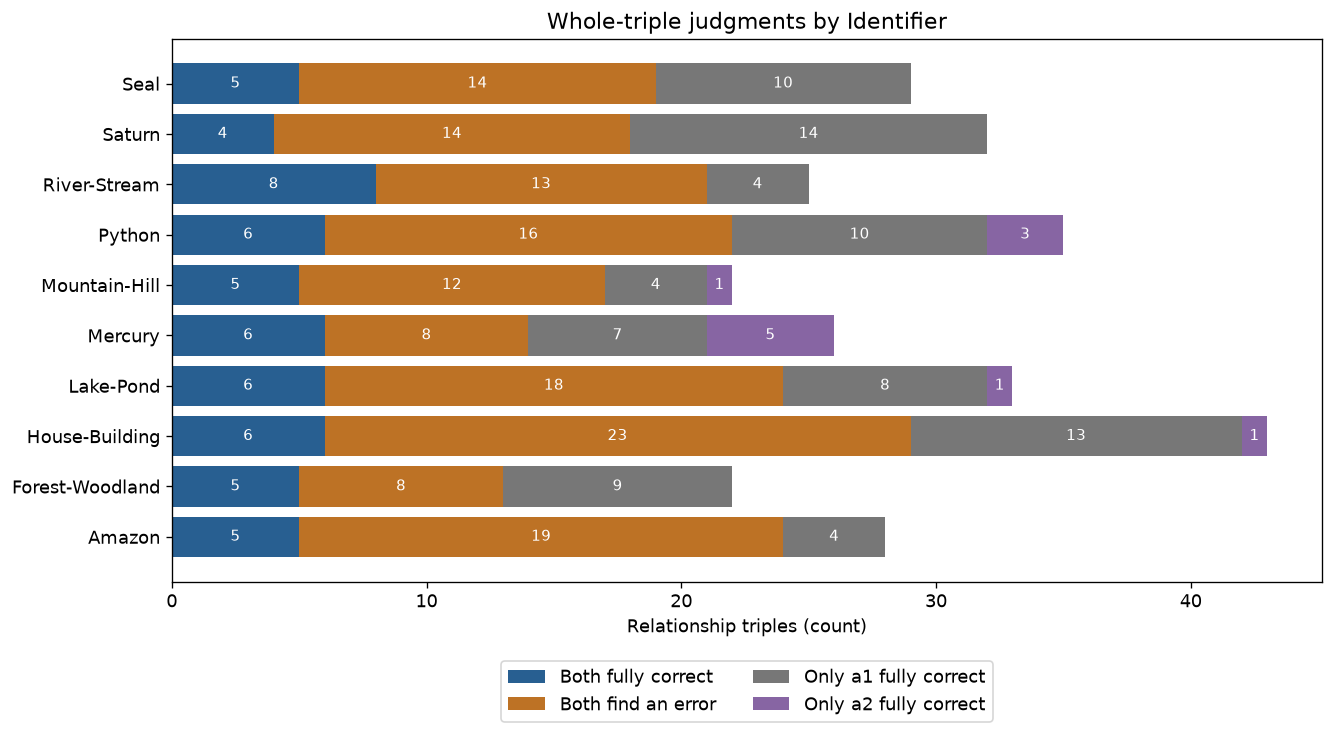

**Answer:** joint approvals occur in 10 groups and joint rejections in 10 groups. Whole-triple agreement is highest in Amazon: 24/28 (85.71%), and lowest in Mercury: 14/26 (53.85%). This does not mean that every triple in a high-agreement group is correct.

In [10]:
identifier_summary = whole.groupby("Identifier")[list(OUTCOMES)].sum()
identifier_summary["n_triples"] = identifier_summary[list(OUTCOMES)].sum(axis=1)
identifier_summary["agreement_pct"] = 100 * (identifier_summary.both_correct + identifier_summary.both_incorrect) / identifier_summary.n_triples
display(identifier_summary.round(2))


def plot_identifier_counts(table):
    fig, ax = plt.subplots(figsize=(11, 6), layout="constrained")
    left = np.zeros(len(table))
    for (column, label), color in zip(OUTCOMES.items(), ["#285f91", "#bd7225", "#777777", "#8765a3"]):
        counts = table[column].to_numpy(dtype=int)
        ax.barh(table.index, counts, left=left, color=color, label=label)
        for i, value in enumerate(counts):
            if value:
                ax.text(left[i]+value/2, i, str(value), ha="center", va="center", color="white", fontsize=9)
        left += counts
    ax.set(xlabel="Relationship triples (count)", title="Whole-triple judgments by Identifier")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5,-0.13), ncol=2)
    return fig


identifier_figure = plot_identifier_counts(identifier_summary)
plt.show()
ranked = identifier_summary.sort_values("agreement_pct", ascending=False)
best, worst = ranked.iloc[0], ranked.iloc[-1]
display(Markdown(
    f"**Answer:** joint approvals occur in {int((identifier_summary.both_correct > 0).sum())} groups and "
    f"joint rejections in {int((identifier_summary.both_incorrect > 0).sum())} groups. "
    f"Whole-triple agreement is highest in {ranked.index[0]}: "
    f"{int(best.both_correct + best.both_incorrect)}/{int(best.n_triples)} ({best.agreement_pct:.2f}%), "
    f"and lowest in {ranked.index[-1]}: {int(worst.both_correct + worst.both_incorrect)}/"
    f"{int(worst.n_triples)} ({worst.agreement_pct:.2f}%). "
    "This does not mean that every triple in a high-agreement group is correct."
))

### Criterion-level context behind the group totals

Whole-triple judgments combine four criteria. The following tables retain per-criterion differences by item type and Identifier. The full counts and denominators remain in `by_group`; undefined kappa is displayed as NaN rather than zero.

In [11]:
def summarize_groups(frame: pd.DataFrame, column: str, labels: dict[str, str]) -> pd.DataFrame:
    """Apply the same criterion calculations independently to each group."""
    records = [{column: name, **metrics(group, criterion, label)}
               for name, group in frame.groupby(column, sort=True)
               for criterion, label in labels.items()]
    return pd.DataFrame(records)


by_type = summarize_groups(common, "item_type", LABELS)
by_group = summarize_groups(common, "Identifier", LABELS)
display(by_type[["item_type", "criterion", "n_shared_items", "n_pairs", "coverage_pct",
                 "agreement_pct", "kappa_cohen", "status"]].round(4))
display(by_group.pivot(index="Identifier", columns="criterion", values="kappa_cohen").round(4))

,item_type,criterion,n_shared_items,n_pairs,coverage_pct,agreement_pct,kappa_cohen,status
0,label,Label matches Wikidata,297,297,100.0000,99.6633,0.6652,calculated
1,label,Entity,297,297,100.0000,37.0370,0.0000,calculated
2,label,Predicate,297,297,100.0000,99.6633,0.0000,calculated
3,label,Direction,297,297,100.0000,99.6633,0.0000,calculated
4,label,Semantic fidelity,297,2,0.6734,0.0000,0.0000,calculated
5,relationship,Label matches Wikidata,295,295,100.0000,100.0000,NaN,undefined: pe=1
6,relationship,Entity,295,295,100.0000,84.4068,0.6836,calculated
7,relationship,Predicate,295,295,100.0000,58.6441,0.2493,calculated
8,relationship,Direction,295,295,100.0000,98.9831,0.0000,calculated
9,relationship,Semantic fidelity,295,295,100.0000,63.7288,0.3115,calculated


criterion,Direction,Entity,Label matches Wikidata,Predicate,Semantic fidelity
Identifier,,,,,
Amazon,NaN,0.4727,1.0000,0.7737,0.5030
Forest-Woodland,0.0,0.1299,1.0000,0.0977,0.0417
House-Building,0.0,0.3686,1.0000,0.6175,0.2668
Lake-Pond,NaN,0.2466,0.9675,0.4273,0.3511
Mercury,0.0,0.1737,1.0000,0.2615,0.2011
Mountain-Hill,NaN,0.4828,1.0000,0.6918,0.4310
Python,NaN,0.2590,1.0000,0.5118,0.1667
River-Stream,NaN,0.2683,1.0000,0.8076,0.6057
Saturn,NaN,0.3134,1.0000,0.2369,0.2000


## 5. Does an incorrect predicate also have an incorrect direction?

Within each rater, select the same relationship triples whose predicate was marked False, then count their direction ratings. Missing ratings remain separate. This is a conditional cross-tabulation, not a causal test.

,rater,predicate_incorrect,direction_incorrect,direction_correct,direction_missing,direction_incorrect_among_observed_pct
0,a1,120,1,119,0,0.83
1,a2,228,0,228,0,0.00


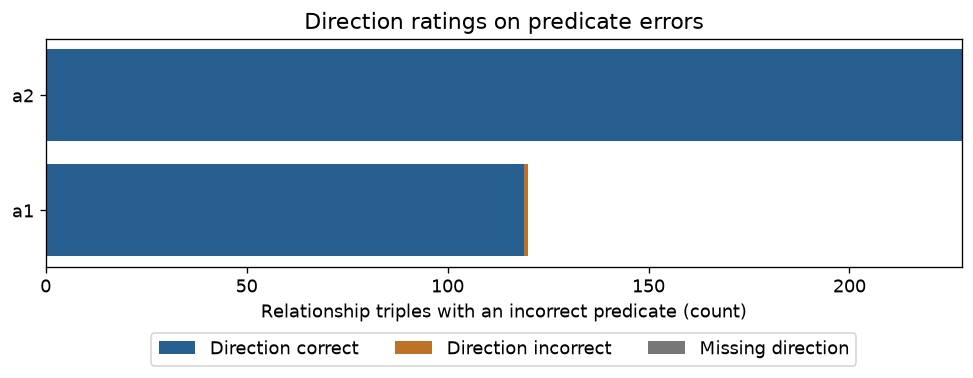

**Answer:** a1: 1 incorrect directions, 119 correct directions, and 0 missing ratings among 120 predicate errors. a2: 0 incorrect directions, 228 correct directions, and 0 missing ratings among 228 predicate errors.

In [12]:
predicate_direction = pd.DataFrame([predicate_direction_counts(relationships, r) for r in ["a1", "a2"]])
display(predicate_direction.round(2))
fig, ax = plt.subplots(figsize=(8, 3), layout="constrained")
left = np.zeros(len(predicate_direction))
for col, label, color in [("direction_correct", "Direction correct", "#285f91"),
                           ("direction_incorrect", "Direction incorrect", "#bd7225"),
                           ("direction_missing", "Missing direction", "#777777")]:
    counts = predicate_direction[col].to_numpy()
    ax.barh(predicate_direction.rater, counts, left=left, label=label, color=color)
    left += counts
ax.set(xlabel="Relationship triples with an incorrect predicate (count)", title="Direction ratings on predicate errors")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=3)
plt.show()
display(Markdown("**Answer:** " + " ".join(
    f"{r.rater}: {r.direction_incorrect} incorrect directions, {r.direction_correct} correct directions, "
    f"and {r.direction_missing} missing ratings among {r.predicate_incorrect} predicate errors."
    for r in predicate_direction.itertuples())))

## 6. Do raters agree on explicitly unresolved entity corrections?

There is no structured “not found” field. We use explicit “não determinada”/“nao determinada” and equivalent unresolved phrases in the entity-correction field as a proxy. This indicates an unresolved proposed correction, not a confirmed failed Wikidata search. A blank or a proposed entity written without a QID is not evidence of failure. See `unresolved_evidence` for the original annotations.

Agreement below concerns the rating of the original entity or relation, not agreement that both raters failed to find a replacement.

,a1_explicit,a2_explicit,both_explicit,either_explicit
0,71,0,0,71


,criterion,n_pairs,both_incorrect,both_correct,joint_rejection_pct
0,Entity,71,58,0,81.69
1,Semantic fidelity,71,70,0,98.59


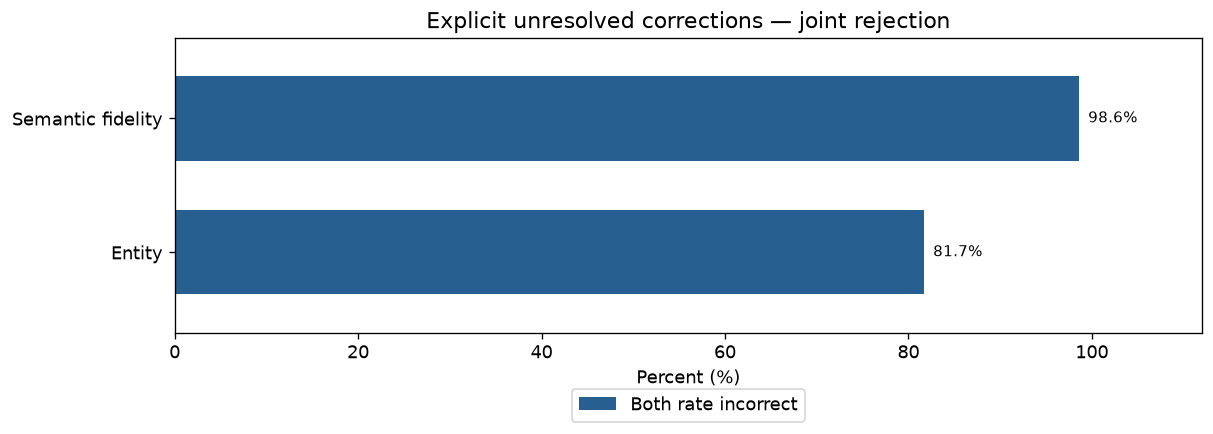

**Answer:** Both reject entity in 58/71 flagged items (81.69%). Both reject semantic fidelity in 70/71 flagged items (98.59%). Marker absence is not evidence of successful resolution; the files cannot establish a shared search failure.

In [13]:
unresolved_a1 = unresolved_flags(common, "a1")
unresolved_a2 = unresolved_flags(common, "a2")
flagged = common.loc[unresolved_a1 | unresolved_a2].copy()
display(pd.DataFrame([{"a1_explicit": int(unresolved_a1.sum()), "a2_explicit": int(unresolved_a2.sum()),
                       "both_explicit": int((unresolved_a1 & unresolved_a2).sum()), "either_explicit": len(flagged)}]))
unresolved_evidence = flagged[KEY + ["entidades_adequadas PREENCHER SE INCORRETO_a1",
                                     "entidades_adequadas PREENCHER SE INCORRETO_a2"]].copy()
unresolved_summary = category_table(flagged, {"entidade_correta": "Entity", "fidelidade_semantica": "Semantic fidelity"})
unresolved_summary["joint_rejection_pct"] = [percent(int(r.both_incorrect), int(r.n_pairs)) for r in unresolved_summary.itertuples()]
display(unresolved_summary[["criterion", "n_pairs", "both_incorrect", "both_correct", "joint_rejection_pct"]].round(2))
unresolved_figure = grouped_percent_chart(unresolved_summary, ["joint_rejection_pct"],
                                         ["Both rate incorrect"], "Explicit unresolved corrections — joint rejection")
plt.show()
display(Markdown("**Answer:** " + " ".join(
    f"Both reject {r.criterion.lower()} in {r.both_incorrect}/{r.n_pairs} flagged items ({r.joint_rejection_pct:.2f}%)."
    for r in unresolved_summary.itertuples()) +
    " Marker absence is not evidence of successful resolution; the files cannot establish a shared search failure."))

## 7. How similar are the final RDF graphs?

This compares **a1 `rdf completo`** with **a2 `rdf corrigido`**, one final graph per Identifier. Graphs are parsed with RDFLib and compared as sets of RDF terms: prefix names, triple order, and Turtle layout do not affect equality. Parsed literal values, language tags, datatypes, and IRIs remain significant. RDFLib may normalize typed-literal lexical forms; this is not a byte-for-byte Turtle comparison. No semantic equivalence between different predicates or entities is assumed, and no external factual claims are fetched.

**Jaccard similarity = shared / union.** Also report shared/a1, shared/a2, and Dice = 2×shared/(a1+a2); neither graph is treated as ground truth. Counts are scoped by Identifier, so a triple occurring in different source groups remains a separate observation. This is graph overlap, not inter-rater kappa.

`rdfs:label` triples are reported separately from relations because shared labels can inflate apparent structural similarity. Relations include every predicate except `rdfs:label`, including literal-valued objects. Entity overlap uses only subject/object IRIs occurring in relations. Directed endpoint pairs ignore predicates; undirected pairs additionally ignore direction. These projections collapse multiplicity and cannot be interpreted as counts of edits.

The parser fails visibly on invalid Turtle, duplicate/missing graph identifiers, mismatched groups, or blank nodes requiring an isomorphism-aware comparison. A fallback decodes escaped layout newlines only outside quoted literals; the parsing audit records whether it was used.

In [14]:
from rdf_comparison import load_final_graphs, compare_graphs, relation_set, projections, mismatch_candidates, exclusive_triples, display_term

graphs_a1, graph_audit_a1 = load_final_graphs(INPUTS["a1"], "rdf completo")
graphs_a2, graph_audit_a2 = load_final_graphs(INPUTS["a2"], "rdf corrigido")
graph_audit = pd.concat([graph_audit_a1, graph_audit_a2], ignore_index=True)
graph_by_identifier, graph_similarity = compare_graphs(graphs_a1, graphs_a2)
display(graph_audit)
display(graph_similarity.round(2))
relation_similarity = graph_by_identifier.loc[graph_by_identifier.dimension == "Relation triples"].copy()
display(relation_similarity.drop(columns="dimension").round(2))

,Identifier,file,column,excel_row,triples,parsing
0,House-Building,a1-rdf.xlsx,rdf completo,2,45,as stored
1,River-Stream,a1-rdf.xlsx,rdf completo,87,29,as stored
2,Python,a1-rdf.xlsx,rdf completo,135,50,as stored
3,Mercury,a1-rdf.xlsx,rdf completo,207,31,as stored
4,Saturn,a1-rdf.xlsx,rdf completo,260,40,as stored
5,Amazon,a1-rdf.xlsx,rdf completo,325,29,as stored
6,Seal,a1-rdf.xlsx,rdf completo,383,31,as stored
7,Mountain-Hill,a1-rdf.xlsx,rdf completo,442,25,as stored
8,Lake-Pond,a1-rdf.xlsx,rdf completo,487,30,as stored
9,Forest-Woodland,a1-rdf.xlsx,rdf completo,549,33,as stored


,dimension,a1,a2,shared,only_a1,only_a2,jaccard_pct,shared_of_a1_pct,shared_of_a2_pct,dice_pct
0,All RDF triples,343,372,271,72,101,61.04,79.01,72.85,75.80
1,Label triples,172,188,157,15,31,77.34,91.28,83.51,87.22
2,Relation triples,171,184,114,57,70,47.30,66.67,61.96,64.23
3,Endpoint entity IRIs,172,188,161,11,27,80.90,93.60,85.64,89.44
4,Predicates,86,79,65,21,14,65.00,75.58,82.28,78.79
5,Directed endpoint pairs,163,181,150,13,31,77.32,92.02,82.87,87.21
6,Undirected endpoint pairs,163,180,150,13,30,77.72,92.02,83.33,87.46


,Identifier,a1,a2,shared,only_a1,only_a2,jaccard_pct,shared_of_a1_pct,shared_of_a2_pct,dice_pct
2,Amazon,14,14,14,0,0,100.00,100.00,100.00,100.00
9,Forest-Woodland,17,19,7,10,12,24.14,41.18,36.84,38.89
16,House-Building,23,23,10,13,13,27.78,43.48,43.48,43.48
23,Lake-Pond,16,22,11,5,11,40.74,68.75,50.00,57.89
30,Mercury,15,19,13,2,6,61.90,86.67,68.42,76.47
37,Mountain-Hill,12,12,10,2,2,71.43,83.33,83.33,83.33
44,Python,25,24,18,7,6,58.06,72.00,75.00,73.47
51,River-Stream,15,17,13,2,4,68.42,86.67,76.47,81.25
58,Saturn,19,18,9,10,9,32.14,47.37,50.00,48.65
65,Seal,15,16,9,6,7,40.91,60.00,56.25,58.06


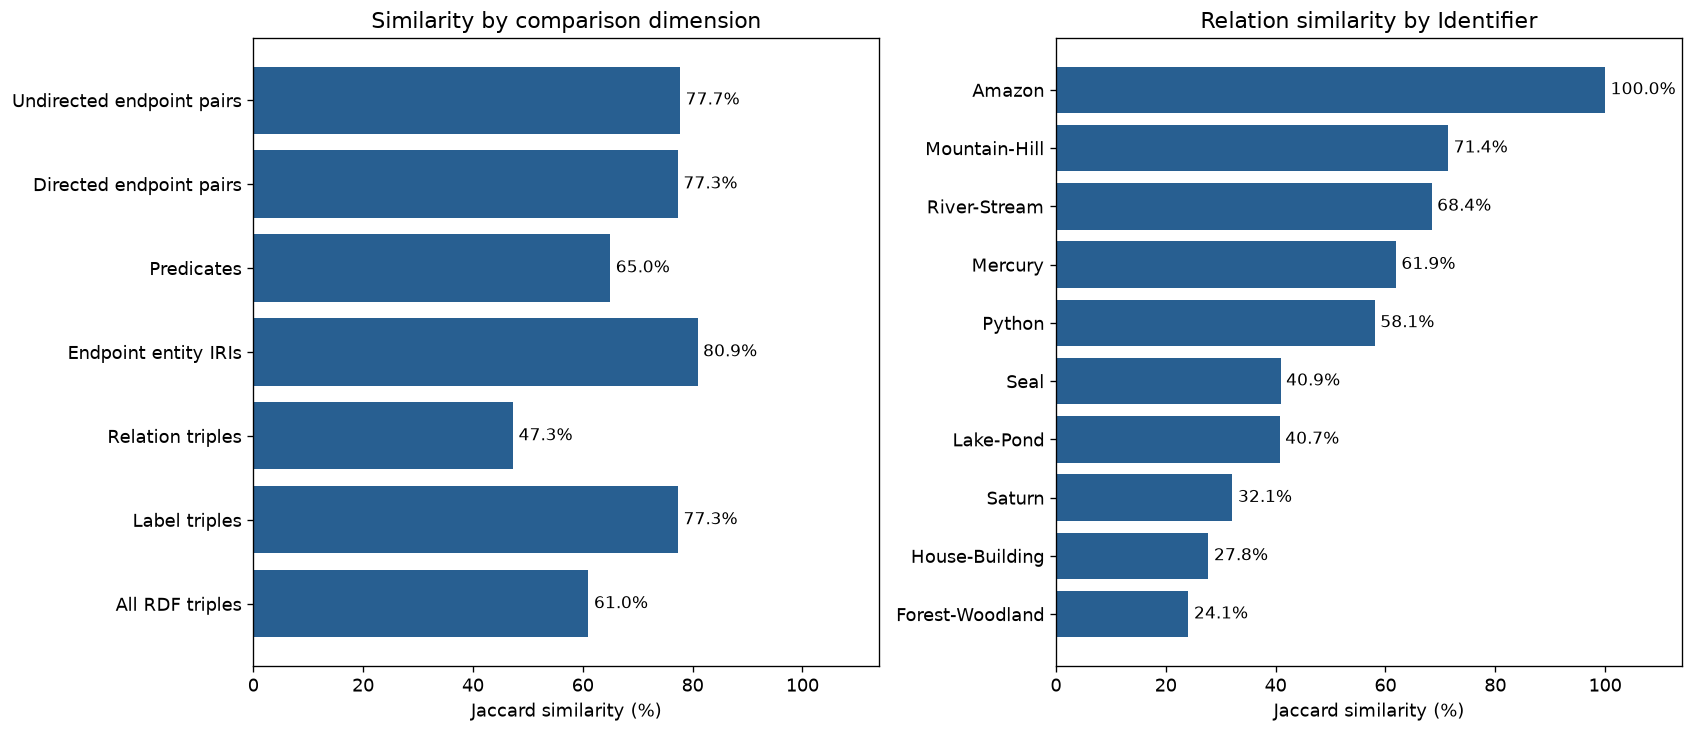

**Answer:** a1 contains 171 relations and a2 contains 184; 114 are identical. Jaccard similarity is 47.30%, with 66.67% of a1 and 61.96% of a2 shared (Dice 64.23%). Ignoring predicates, directed endpoint-pair similarity is 77.32%. This indicates substantial shared connectivity despite differing relation names.

In [15]:
def plot_graph_similarity(totals, groups):
    fig, axes = plt.subplots(1, 2, figsize=(14, 6), layout="constrained")
    panels = [(totals, "dimension", "Similarity by comparison dimension"),
              (groups.sort_values("jaccard_pct"), "Identifier", "Relation similarity by Identifier")]
    for ax, (table, label, title) in zip(axes, panels):
        ax.barh(table[label], table.jaccard_pct, color="#285f91")
        for i, row in enumerate(table.itertuples()):
            ax.text(row.jaccard_pct+1, i, f"{row.jaccard_pct:.1f}%", va="center", fontsize=10)
        ax.set(xlim=(0, 114), xlabel="Jaccard similarity (%)", title=title)
    return fig


graph_figure = plot_graph_similarity(graph_similarity, relation_similarity)
plt.show()
relation_total = graph_similarity.set_index("dimension").loc["Relation triples"]
endpoint_total = graph_similarity.set_index("dimension").loc["Directed endpoint pairs"]
display(Markdown(
    f"**Answer:** a1 contains {int(relation_total.a1)} relations and a2 contains {int(relation_total.a2)}; "
    f"{int(relation_total.shared)} are identical. Jaccard similarity is {relation_total.jaccard_pct:.2f}%, "
    f"with {relation_total.shared_of_a1_pct:.2f}% of a1 and {relation_total.shared_of_a2_pct:.2f}% of a2 shared "
    f"(Dice {relation_total.dice_pct:.2f}%). Ignoring predicates, directed endpoint-pair similarity is "
    f"{endpoint_total.jaccard_pct:.2f}%. This indicates substantial shared connectivity despite differing relation names."
))

### What differs: predicates, endpoints, or direction?

For each exclusive relation, search exclusive relations in the other graph for four kinds of evidence:

- **Predicate only:** identical subject and object, different predicate.
- **Direction only:** the same predicate with subject and object swapped.
- **One endpoint only:** the same predicate and one matching endpoint, with the other endpoint different.
- **Direction and predicate:** swapped endpoints and a different predicate.

These are **candidate correspondences**, not proven corrections or a one-to-one edit history. An exclusive triple may have several candidate counterparts or kinds; counts can overlap and must not be summed. Some exclusive triples may reflect additions/removals or multiple changes, which cannot be separated from graph sets alone. Entity inventories and exact examples provide complementary evidence.

In [16]:
graph_candidates = mismatch_candidates(graphs_a1, graphs_a2)
graph_exclusive = exclusive_triples(graphs_a1, graphs_a2)
KINDS = ["Predicate only", "Direction only", "One endpoint only", "Direction and predicate"]


def candidate_counts(candidates, exclusive):
    records = []
    for source in ["a1", "a2"]:
        items = exclusive.loc[exclusive.source == source]
        keys = set(zip(items.Identifier, items.triple))
        all_matches = candidates.loc[candidates.source == source]
        matched_keys = set(zip(all_matches.Identifier, all_matches.triple))
        for kind in KINDS:
            matches = all_matches.loc[all_matches.kind == kind]
            n = len(set(zip(matches.Identifier, matches.triple)))
            records.append({"source": source, "candidate_difference": kind,
                            "exclusive_triples_with_candidate": n, "exclusive_triples": len(keys),
                            "pct_of_exclusive": percent(n, len(keys))})
        records.append({"source": source, "candidate_difference": "No candidate under these rules",
                        "exclusive_triples_with_candidate": len(keys-matched_keys),
                        "exclusive_triples": len(keys),
                        "pct_of_exclusive": percent(len(keys-matched_keys), len(keys))})
    return pd.DataFrame(records)


graph_difference_counts = candidate_counts(graph_candidates, graph_exclusive)
display(graph_difference_counts.round(2))


def readable_candidates(candidates, left, right):
    rows = []
    for row in candidates.loc[candidates.source == "a1"].itertuples():
        # Resolve exact N3 terms back to the already parsed triples for display.
        a = next(t for t in left[row.Identifier] if tuple(x.n3() for x in t) == row.triple)
        b = next(t for t in right[row.Identifier] if tuple(x.n3() for x in t) == row.candidate)
        rows.append({"Identifier": row.Identifier, "difference": row.kind,
                     "a1": " → ".join(display_term(x, left[row.Identifier]) for x in a),
                     "a2": " → ".join(display_term(x, right[row.Identifier]) for x in b)})
    return pd.DataFrame(rows, columns=["Identifier", "difference", "a1", "a2"])


graph_difference_examples = readable_candidates(graph_candidates, graphs_a1, graphs_a2)
display(graph_difference_examples.loc[graph_difference_examples.difference == "Predicate only"].groupby("Identifier").head(1))


def entity_differences(left, right):
    rows = []
    for identifier in sorted(left):
        a = projections(relation_set(left[identifier]))["Endpoint entity IRIs"]
        b = projections(relation_set(right[identifier]))["Endpoint entity IRIs"]
        for source, entities, graph in [("a1", a-b, left[identifier]), ("a2", b-a, right[identifier])]:
            rows.extend({"Identifier": identifier, "source": source, "entity": display_term(entity, graph),
                         "IRI": str(entity)} for entity in sorted(entities, key=str))
    return pd.DataFrame(rows, columns=["Identifier", "source", "entity", "IRI"])


graph_entity_differences = entity_differences(graphs_a1, graphs_a2)
display(graph_entity_differences)
predicate_matches = graph_difference_counts.loc[
    (graph_difference_counts.source == "a1") & (graph_difference_counts.candidate_difference == "Predicate only")].iloc[0]
reverse_count = int(graph_difference_counts.loc[
    graph_difference_counts.candidate_difference.isin(["Direction only", "Direction and predicate"]),
    "exclusive_triples_with_candidate"].sum())
entities = graph_similarity.set_index("dimension").loc["Endpoint entity IRIs"]
display(Markdown(
    f"**Interpretation:** {int(predicate_matches.exclusive_triples_with_candidate)}/{int(predicate_matches.exclusive_triples)} "
    f"exclusive a1 relations ({predicate_matches.pct_of_exclusive:.2f}%) have an exclusive a2 counterpart with identical "
    f"ordered endpoints and a different predicate. Entity-IRI overlap is {entities.jaccard_pct:.2f}%, with "
    f"{int(entities.only_a1)} Identifier-scoped entities unique to a1 and {int(entities.only_a2)} unique to a2. "
    f"There are {reverse_count} exclusive triples with a reversed-endpoint candidate under the stated rules. "
    "These candidate counts overlap: use the endpoint and entity similarities alongside them; do not sum them as edit counts. "
    "These structural comparisons do not determine which RDF is factually correct."
))

,source,candidate_difference,exclusive_triples_with_candidate,exclusive_triples,pct_of_exclusive
0,a1,Predicate only,37,57,64.91
1,a1,Direction only,0,57,0.00
2,a1,One endpoint only,9,57,15.79
3,a1,Direction and predicate,0,57,0.00
4,a1,No candidate under these rules,14,57,24.56
5,a2,Predicate only,37,70,52.86
6,a2,Direction only,0,70,0.00
7,a2,One endpoint only,9,70,12.86
8,a2,Direction and predicate,0,70,0.00
9,a2,No candidate under these rules,26,70,37.14


,Identifier,difference,a1,a2
0,Forest-Woodland,Predicate only,Woodland [Q2615722] → be → England [Q21],Woodland [Q2615722] → beIn → England [Q21]
11,House-Building,Predicate only,house [Q3947] → condition → systems [Q131179478],house [Q3947] → outfitWith → systems [Q131179478]
22,Lake-Pond,Predicate only,lake [Q23397] → fix → physical object [Q223557],lake [Q23397] → be → physical object [Q223557]
27,Mercury,Predicate only,Mercury [Q1231263] → beIn → Albertville [Q159469],Mercury [Q1231263] → beTo → Albertville [Q159469]
30,Mountain-Hill,Predicate only,mountain [Q8502] → have → portion [Q2105114],mountain [Q8502] → be → portion [Q2105114]
32,Python,Predicate only,Python [Q271218] → be → snake [Q2102],Python [Q271218] → constrict → snake [Q2102]
35,River-Stream,Predicate only,river [Q4022] → inside → Caves [Q200886],river [Q4022] → flowInside → Caves [Q200886]
36,Saturn,Predicate only,Saturn [Q134388] → be → mythology [Q9134],Saturn [Q134388] → beIn → mythology [Q9134]
44,Seal,Predicate only,Seal [Q218091] → be → Grammy Awards [Q41254],Seal [Q218091] → beOf → Grammy Awards [Q41254]


,Identifier,source,entity,IRI
0,Forest-Woodland,a2,municipality [Q15284],http://www.wikidata.org/entity/Q15284
1,Forest-Woodland,a2,Civil [Q37552616],http://www.wikidata.org/entity/Q37552616
2,Forest-Woodland,a2,town [Q3957],http://www.wikidata.org/entity/Q3957
3,Forest-Woodland,a2,19 [Q39850],http://www.wikidata.org/entity/Q39850
4,House-Building,a1,response to stimulus [Q14859560],http://www.wikidata.org/entity/Q14859560
5,House-Building,a1,Air [Q318452],http://www.wikidata.org/entity/Q318452
6,House-Building,a1,soil [Q36133],http://www.wikidata.org/entity/Q36133
7,House-Building,a2,Reasons [Q37467962],http://www.wikidata.org/entity/Q37467962
8,House-Building,a2,Prestige [Q97751506],http://www.wikidata.org/entity/Q97751506
9,Lake-Pond,a2,metre [Q11573],http://www.wikidata.org/entity/Q11573


**Interpretation:** 37/57 exclusive a1 relations (64.91%) have an exclusive a2 counterpart with identical ordered endpoints and a different predicate. Entity-IRI overlap is 80.90%, with 11 Identifier-scoped entities unique to a1 and 27 unique to a2. There are 0 exclusive triples with a reversed-endpoint candidate under the stated rules. These candidate counts overlap: use the endpoint and entity similarities alongside them; do not sum them as edit counts. These structural comparisons do not determine which RDF is factually correct.

In [17]:
# Reconcile the actual graph sets. Synthetic parser/candidate tests live in tests/test_exam_review.py.
for row in graph_similarity.itertuples():
    assert row.shared + row.only_a1 == row.a1
    assert row.shared + row.only_a2 == row.a2
for row in relation_similarity.itertuples():
    assert row.shared == len(relation_set(graphs_a1[row.Identifier]) & relation_set(graphs_a2[row.Identifier]))
display(Markdown(f"**Graph checks passed:** {len(graph_audit)} final graphs parsed and set counts reconcile."))

**Graph checks passed:** 20 final graphs parsed and set counts reconcile.

## 8. Which disagreements become adjudication cases?

We first retain the item/criterion audit, then examine the actual exported JSON. These are different units: one triple may have several criterion issues, while the JSON contains one object per annotation case or competing RDF endpoint group.

Missing ratings appear in the audit but are not automatically disagreements. The JSON selects four explicit subsets rather than exporting every absent answer or exclusive graph triple.

In [18]:
def criterion_issues(frame: pd.DataFrame, criterion: str, label: str,
                     columns: list[str]) -> pd.DataFrame:
    """Return missing ratings and disagreements, preserving original context."""
    left, right = rating_columns(frame, criterion)
    pending = left.isna() | right.isna()
    disagree = ~pending & left.ne(right).fillna(False)
    selection = frame.loc[pending | disagree, columns].copy()
    return selection.assign(
        criterion=label, a1=left.loc[selection.index], a2=right.loc[selection.index],
        issue=np.where(pending.loc[selection.index], "missing rating", "disagreement"))


def build_review_queue(frame: pd.DataFrame, key: list[str], labels: dict[str, str],
                       context_columns: list[str]) -> pd.DataFrame:
    columns = key + [column for column in context_columns if column in frame]
    issues = [criterion_issues(frame, criterion, label, columns)
              for criterion, label in labels.items()]
    return pd.concat(issues, ignore_index=True)


CONTEXT_COLUMNS = ["excel_row_a1", "excel_row_a2", "relacao_traduzida_a1",
                   "observacao_a1", "observacao_a2", "rdf corrigido_a1", "rdf corrigido_a2"]
review_queue = build_review_queue(common, KEY, LABELS, CONTEXT_COLUMNS)
display(review_queue.groupby(["criterion", "issue"]).size().unstack(fill_value=0))
display(review_queue[KEY + ["criterion", "a1", "a2", "issue"]].head(20))

issue,disagreement,missing rating
criterion,,
Direction,4,0
Entity,233,0
Label matches Wikidata,1,0
Predicate,123,0
Semantic fidelity,109,295


,Identifier,tripla_original,criterion,a1,a2,issue
0,Lake-Pond,wd:Q3253281 kg:rdf-schema#label wd:pond,Label matches Wikidata,True,False,disagreement
1,Amazon,wd:Q11790733 kg:rdf-schema#label wd:North,Entity,False,True,disagreement
2,Amazon,wd:Q155 kg:rdf-schema#label wd:Brazil,Entity,False,True,disagreement
3,Amazon,wd:Q15982450 kg:rdf-schema#label wd:music stre...,Entity,False,True,disagreement
4,Amazon,wd:Q161726 kg:rdf-schema#label wd:multinationa...,Entity,False,True,disagreement
5,Amazon,wd:Q1665657 kg:rdf-schema#label wd:Intelligence,Entity,False,True,disagreement
6,Amazon,wd:Q16865769 kg:rdf-schema#label wd:Corner,Entity,False,True,disagreement
7,Amazon,wd:Q173799 kg:rdf-schema#label wd:entertainment,Entity,False,True,disagreement
8,Amazon,wd:Q37038 kg:rdf-schema#label wd:advertising,Entity,False,True,disagreement
9,Amazon,wd:Q3884 kg:rdf-schema#label wd:Amazon,Entity,False,True,disagreement


### Read the adjudication dataset

`disagreements.json` contains unique `cases` and subset indexes referencing their IDs. A case can belong to more than one subset without being duplicated. The tables show both unique-case counts and overlapping memberships. Existing review statuses and decisions are read as saved and never overwritten.

If the JSON is missing, run `python ExamReview/export_disagreements.py` from the repository root. If its source hashes differ, generate a new round with a new filename and update `DISAGREEMENTS_PATH` below; do not overwrite human decisions just to refresh this analysis.

In [19]:
from export_disagreements import load_export, adjudication_tables

DISAGREEMENTS_PATH = ROOT / "data" / "disagreements.json"
if not DISAGREEMENTS_PATH.is_file():
    raise FileNotFoundError("Generate the adjudication JSON with ExamReview/export_disagreements.py first.")
disagreements, disagreements_hash = load_export(DISAGREEMENTS_PATH, INPUTS)

case_table, subset_summary = adjudication_tables(disagreements)
SUBSET_NAMES = {"unilateral_approvals": "Unilateral approval",
                "shared_rejection_diagnosis_divergence": "Different diagnoses",
                "competing_rdf_relations": "Competing RDF relations",
                "unilateral_unresolved_entities": "Unilateral unresolved entity"}
display(subset_summary[["title", "cases", "pct_of_unique_cases"]].round(2))
display(case_table.groupby("case_type").size().rename("unique_cases").to_frame())
display(pd.DataFrame([disagreements["coverage"]]).T.rename(columns={0:"items"}))
display(Markdown(
    f"**Adjudication dataset:** {len(case_table)} unique cases; "
    f"{int(case_table.membership_count.sum())} subset memberships; "
    f"{int(case_table.membership_count.gt(1).sum())} cases belong to multiple subsets. "
    "Percentages by subset overlap and must not be summed as a partition of the dataset."
))

,title,cases,pct_of_unique_cases
0,Unilateral approvals (critical disagreement),94,38.06
1,Different diagnoses in shared rejections,63,25.51
2,Competing relations in final RDF graphs,43,17.41
3,Unilateral explicitly unresolved entity correc...,71,28.74


,unique_cases
case_type,
annotation,204
rdf_relation_group,43


,items
matched_items,592
relationship_items,295
excluded_label_items,297
unmatched_items,0
incomplete_relationship_items,0
unpaired_relation_triples_a1,15
unpaired_relation_triples_a2,31
exclusive_label_triples_a1,15
exclusive_label_triples_a2,31


**Adjudication dataset:** 247 unique cases; 271 subset memberships; 24 cases belong to multiple subsets. Percentages by subset overlap and must not be summed as a partition of the dataset.

### Which types dominate, and how do they overlap?

The first chart counts cases in each subset; the second uses exact membership combinations, so its bars are mutually exclusive and sum to the unique-case total. Annotation cases and RDF cases have different units and should not be interpreted as one set of independently evaluated triples.

,combination,unique_cases
3,Unilateral approval,93
5,Unilateral unresolved entity,47
0,Competing RDF relations,43
1,Different diagnoses,40
2,Different diagnoses + Unilateral unresolved en...,23
4,Unilateral approval + Unilateral unresolved en...,1


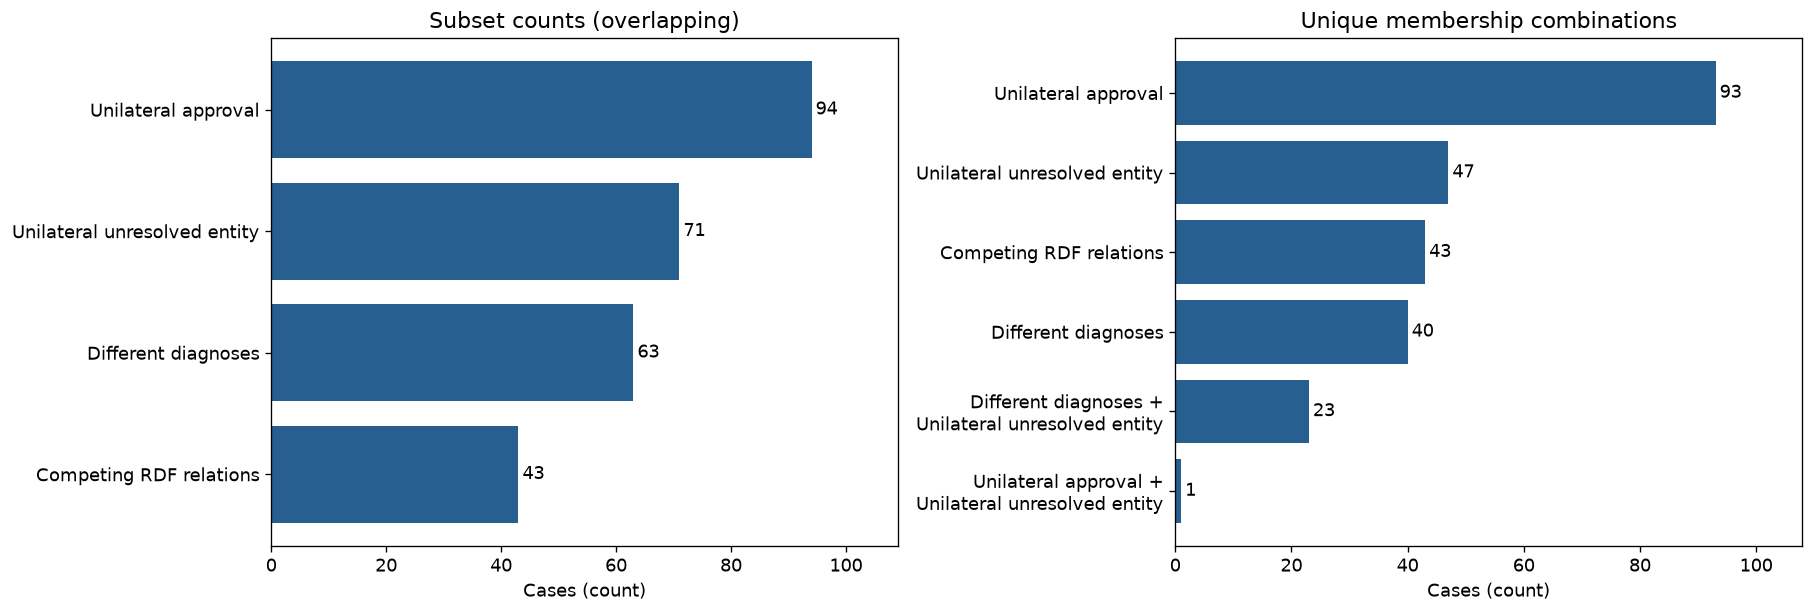

In [20]:
case_table["combination"] = case_table.subset_ids.map(
    lambda keys: " + ".join(SUBSET_NAMES[key] for key in sorted(keys)))
case_combinations = case_table.groupby("combination").size().rename("unique_cases").reset_index()
display(case_combinations.sort_values("unique_cases", ascending=False))


def plot_case_types(subsets, combinations):
    fig, axes = plt.subplots(1, 2, figsize=(15, 5), layout="constrained")
    a = subsets.sort_values("cases")
    b = combinations.sort_values("unique_cases")
    panels = [(a.subset.map(SUBSET_NAMES), a.cases, "Subset counts (overlapping)"),
              (b.combination.str.replace(" + ", " +\n", regex=False), b.unique_cases, "Unique membership combinations")]
    for ax, (names, values, title) in zip(axes, panels):
        ax.barh(names, values, color="#285f91")
        for i, value in enumerate(values):
            ax.text(value+0.7, i, str(value), va="center")
        ax.set(xlim=(0, max(1, values.max())*1.16), xlabel="Cases (count)", title=title)
    return fig


case_type_figure = plot_case_types(subset_summary, case_combinations)
plt.show()
assert case_combinations.unique_cases.sum() == len(case_table)

### Where should review effort be directed?

The table includes unique cases per Identifier, then memberships by type. The type columns overlap; their row sums can exceed the unique-case count. The chart separates this distinction explicitly. Review status summarizes the saved JSON rather than inferring progress from agreement metrics.

,unique_cases,unilateral_approvals,shared_rejection_diagnosis_divergence,competing_rdf_relations,unilateral_unresolved_entities
Identifier,,,,,
Amazon,19,4,4,0,11
Forest-Woodland,24,9,7,8,0
House-Building,37,14,8,10,7
Lake-Pond,31,9,11,5,14
Mercury,20,12,4,2,2
Mountain-Hill,11,5,2,2,2
Python,32,13,8,4,9
River-Stream,17,4,5,1,10
Saturn,35,14,10,7,12


,,cases
case_type,status,
annotation,pending,204
rdf_relation_group,pending,43


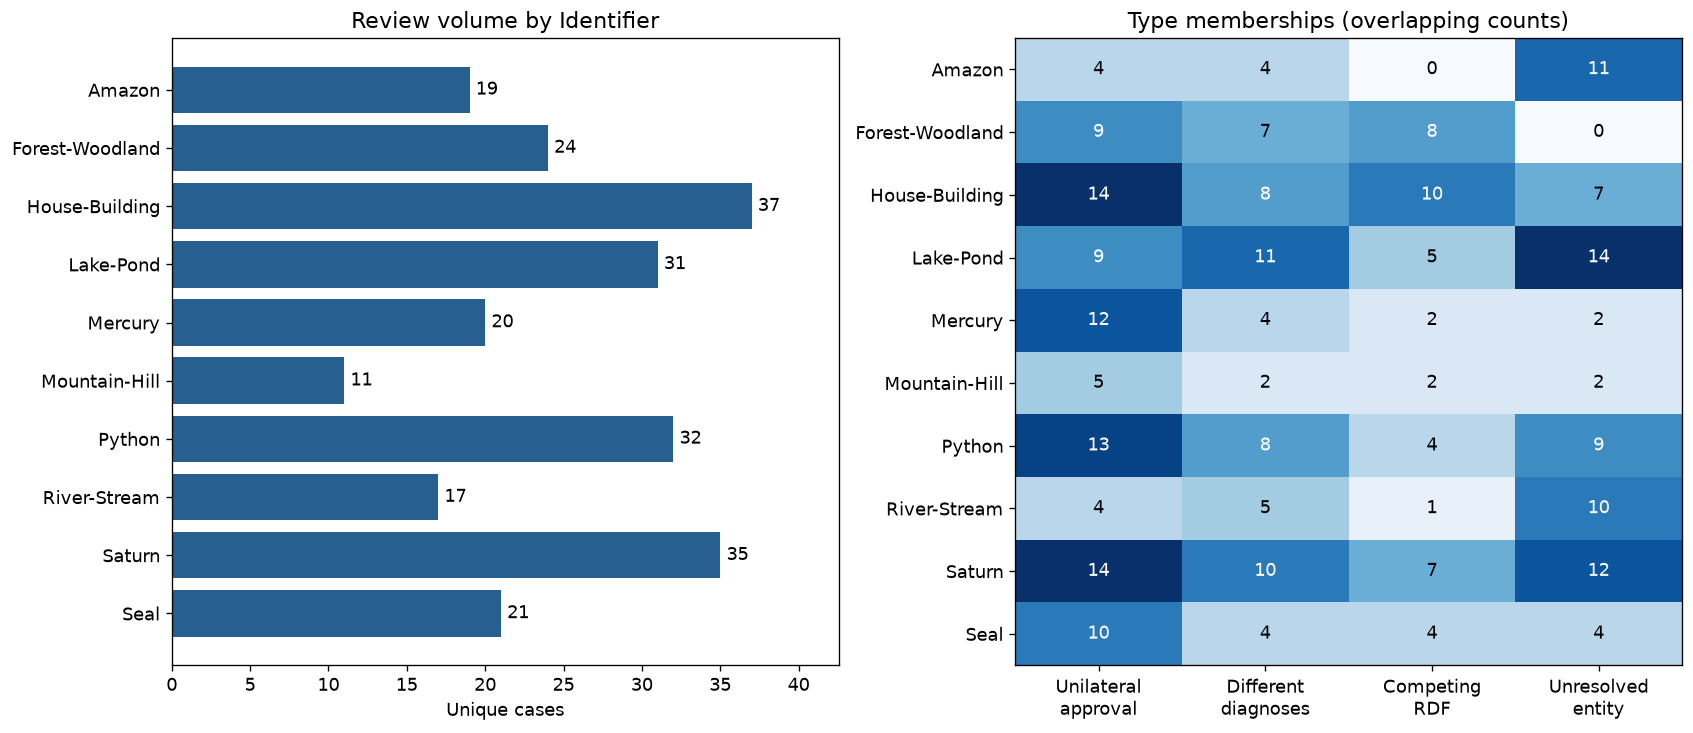

,case_id,Identifier,case_type,combination,status
0,029c3a060915ac90812b46b5,Amazon,annotation,Unilateral approval,pending
1,06fe152244ff8881df0aec75,Amazon,annotation,Different diagnoses,pending
2,0a57bc3e0606d746ca8c3677,Amazon,annotation,Unilateral unresolved entity,pending
3,19305d69eb3359b13f7fdf27,Amazon,annotation,Unilateral unresolved entity,pending
4,434b99f1d6e4c5c39915bd34,Amazon,annotation,Unilateral approval,pending
5,5b7a47f853429dd2dbfe2324,Amazon,annotation,Unilateral approval,pending
6,5c5e1011dd6503ee9e3180c9,Amazon,annotation,Different diagnoses,pending
7,5db3ce2840c30629dc463898,Amazon,annotation,Unilateral unresolved entity,pending
8,69ac92f08e90d622c0829d68,Amazon,annotation,Unilateral unresolved entity,pending
9,6c2f9926eae825cf1bde8d22,Amazon,annotation,Different diagnoses,pending


**Review priorities:** Unilateral approvals (critical disagreement) is the largest subset (94 cases). House-Building has the largest unique review volume (37 cases). These are workload counts, not evidence that one group is intrinsically less reliable. Use case IDs to adjudicate shared memberships once, then record approved ratings or RDF alternatives in the existing JSON.

In [21]:
memberships = case_table.explode("subset_ids")
case_counts_by_identifier = case_table.groupby("Identifier").size().rename("unique_cases").to_frame()
type_counts_by_identifier = pd.crosstab(memberships.Identifier, memberships.subset_ids).reindex(
    index=case_counts_by_identifier.index, columns=list(SUBSET_NAMES), fill_value=0)
display(case_counts_by_identifier.join(type_counts_by_identifier))
display(case_table.groupby(["case_type", "status"]).size().rename("cases").to_frame())


def plot_case_identifiers(unique, by_type):
    fig, axes = plt.subplots(1, 2, figsize=(14, 6), layout="constrained")
    axes[0].barh(unique.index, unique.unique_cases, color="#285f91")
    for i, n in enumerate(unique.unique_cases):
        axes[0].text(n+0.4, i, str(n), va="center")
    axes[0].set(xlim=(0,max(1,unique.unique_cases.max())*1.15), xlabel="Unique cases", title="Review volume by Identifier")
    axes[0].invert_yaxis()
    axes[1].imshow(by_type.to_numpy(), cmap="Blues", vmin=0, aspect="auto")
    maximum = max(1,int(by_type.to_numpy().max()))
    for (i,j), n in np.ndenumerate(by_type.to_numpy()):
        axes[1].text(j,i,str(n),ha="center",va="center",color="white" if n>maximum/2 else "black")
    axes[1].set(xticks=range(len(by_type.columns)),
                xticklabels=["Unilateral\napproval", "Different\ndiagnoses", "Competing\nRDF", "Unresolved\nentity"],
                yticks=range(len(by_type)), yticklabels=by_type.index,
                title="Type memberships (overlapping counts)")
    return fig


case_identifier_figure = plot_case_identifiers(case_counts_by_identifier, type_counts_by_identifier)
plt.show()
display(case_table[["case_id", "Identifier", "case_type", "combination", "status"]].head(12))
if len(case_table):
    top_group = case_counts_by_identifier.unique_cases.idxmax()
    top_type = subset_summary.sort_values("cases", ascending=False).iloc[0]
    display(Markdown(f"**Review priorities:** {top_type.title} is the largest subset ({top_type.cases} cases). "
                     f"{top_group} has the largest unique review volume ({case_counts_by_identifier.loc[top_group,'unique_cases']} cases). "
                     "These are workload counts, not evidence that one group is intrinsically less reliable. "
                     "Use case IDs to adjudicate shared memberships once, then record approved ratings or RDF alternatives in the existing JSON."))
assert file_sha256(DISAGREEMENTS_PATH) == disagreements_hash
assert int(type_counts_by_identifier.to_numpy().sum()) == int(case_table.membership_count.sum())

## Conclusions and next steps

The narrative separates three levels of evidence: judgments on individual criteria, judgments on whole relationship triples, and overlap between final RDF graphs. The adjudication dataset translates selected differences into unique review cases; it is not another reliability metric.

1. Review critical unilateral approvals and differing diagnoses using the source text and all substantive criteria.
2. Compare RDF alternatives within each endpoint group; consider excluded unpaired relations separately when needed.
3. Clarify unresolved-entity markers and missing/not-applicable ratings with the raters.
4. Record decisions, reviewer, and rationale in the JSON. Preserve the input hashes and the documented a1 correction rule.
5. Create and validate an approved dataset separately before rebuilding downstream questions. These notebooks do not apply adjudication automatically.

The following checks reconcile this run and confirm that source workbooks and the adjudication file were preserved.

In [22]:
assert int(whole_counts.sum()) == len(whole)
assert identifier_summary.n_triples.sum() == len(whole)
assert int(whole.same_error_criterion.sum()) <= int(whole_counts.both_incorrect)
for row in category_summary.itertuples():
    assert row.both_correct + row.both_incorrect + row.a1_correct_a2_incorrect + row.a1_incorrect_a2_correct == row.n_pairs
for row in predicate_direction.itertuples():
    assert row.direction_correct + row.direction_incorrect + row.direction_missing == row.predicate_incorrect
for r, (_, audit) in loaded.items():
    assert file_sha256(INPUTS[r]) == audit["sha256"]
display(Markdown("**Validation passed:** counts reconcile and input workbooks are unchanged."))
assert file_sha256(DISAGREEMENTS_PATH) == disagreements_hash


**Validation passed:** counts reconcile and input workbooks are unchanged.